# Game Cheat Detection Lab
**Behavioural anomaly detection for aimbot-style cheating, on synthetic player telemetry**

By Sarah Zafar | Cybersecurity | Game security research

Cheat software leaves behavioural fingerprints. Humans are inconsistent: their reaction times vary and their aim has a natural limit. Aim-assist cheats are suspiciously fast, accurate and consistent. This notebook simulates player telemetry and compares two ways of flagging cheaters:

1. a **rule-based baseline** using robust statistics (the kind of signature-style rule a studio might start with), and
2. an **Isolation Forest**, an unsupervised machine learning model that needs no labelled cheaters.

The main question is the one that matters in real anti-cheat work: **can we catch subtle cheaters without wrongly flagging legitimately skilled players?**

> **Important:** all data here is **synthetic**, generated by the code below. This is a learning demo of the method, not a validated anti-cheat system, and it uses no real game data.

The approach is inspired by published work on server-side behavioural cheat detection, for example Alayed, Frangoudes and Neuman (2013).

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, precision_recall_curve, average_precision_score

rng = np.random.default_rng(42)   # fixed seed so results are reproducible

## 2. Simulate player telemetry
Each row is one player, summarised over many matches. Four groups:

| Group | Description |
|---|---|
| `casual` | typical players: average reactions, modest accuracy |
| `skilled` | legitimately excellent players: fast and accurate, but still human and variable |
| `blatant_cheat` | obvious aimbot: inhuman speed and accuracy |
| `subtle_cheat` | careful cheater: looks plausible, but is *too consistent* |

The subtle cheaters overlap with skilled players on speed and accuracy. The giveaway is low variability, because humans are never that consistent.

In [2]:
def make_group(name, n, label, reaction, react_std, accuracy, headshot, snap):
    return pd.DataFrame({
        "group": name,
        "label": label,                                           # 0 = legitimate, 1 = cheater
        "reaction_ms_mean": np.clip(rng.normal(*reaction, n), 70, None),   # average reaction time (ms)
        "reaction_ms_std":  np.clip(rng.normal(*react_std, n), 3, None),   # how much reaction time varies (ms)
        "accuracy":         rng.beta(*accuracy, n),                        # hit ratio, 0 to 1
        "headshot_ratio":   rng.beta(*headshot, n),                        # share of hits that are headshots
        "snap_speed_deg_s": np.clip(rng.normal(*snap, n), 50, None),       # speed of aim flicks (degrees/second)
    })

df = pd.concat([
    make_group("casual",        450, 0, (260, 35), (55, 12), (5, 15), (2, 12), (220, 45)),
    make_group("skilled",        40, 0, (205, 18), (35,  8), (9, 11), (5, 10), (330, 40)),
    make_group("blatant_cheat",  15, 1, ( 95, 15), ( 8,  3), (18, 2), (14, 3), (900, 120)),
    make_group("subtle_cheat",   25, 1, (165, 12), (14,  4), (12, 8), (8,  6), (480, 50)),
], ignore_index=True)

features = ["reaction_ms_mean", "reaction_ms_std", "accuracy", "headshot_ratio", "snap_speed_deg_s"]
print(f"{len(df)} players, of which {df.label.sum()} are cheaters ({df.label.mean():.1%})")
df.groupby("group")[features].mean().round(2)

530 players, of which 40 are cheaters (7.5%)


,reaction_ms_mean,reaction_ms_std,accuracy,headshot_ratio,snap_speed_deg_s
group,,,,,
blatant_cheat,93.55,8.40,0.88,0.85,899.98
casual,259.35,54.17,0.24,0.14,217.58
skilled,202.83,32.72,0.45,0.35,336.77
subtle_cheat,165.50,14.46,0.56,0.56,483.07


## 3. Look at the data first

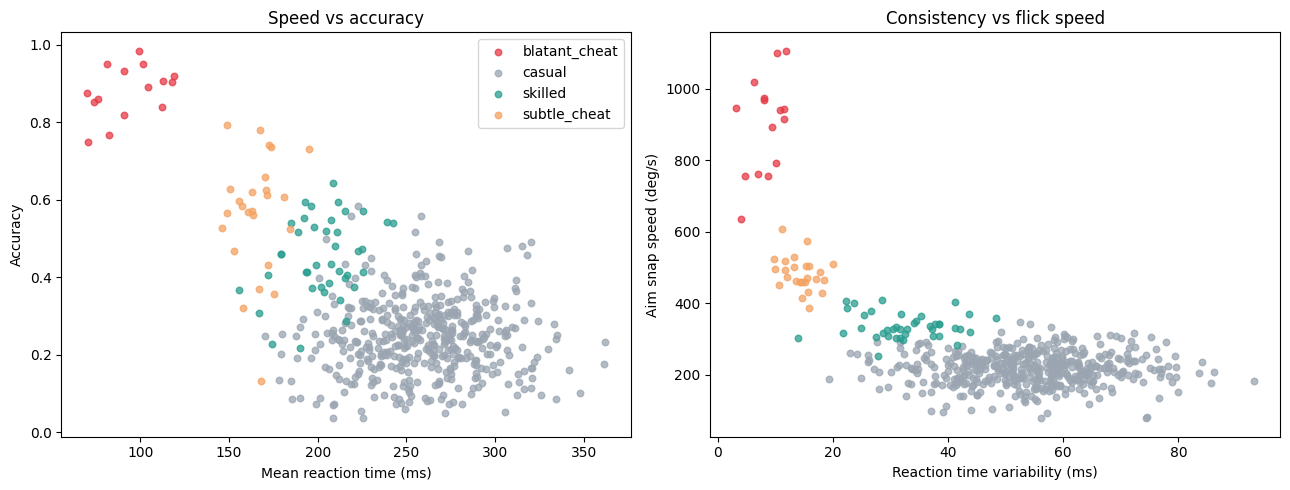

In [3]:
colors = {"casual": "#9aa5b1", "skilled": "#2a9d8f", "blatant_cheat": "#e63946", "subtle_cheat": "#f4a261"}
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for g, sub in df.groupby("group"):
    axes[0].scatter(sub.reaction_ms_mean, sub.accuracy, s=22, alpha=0.75, label=g, color=colors[g])
    axes[1].scatter(sub.reaction_ms_std, sub.snap_speed_deg_s, s=22, alpha=0.75, label=g, color=colors[g])

axes[0].set(xlabel="Mean reaction time (ms)", ylabel="Accuracy", title="Speed vs accuracy")
axes[1].set(xlabel="Reaction time variability (ms)", ylabel="Aim snap speed (deg/s)", title="Consistency vs flick speed")
axes[0].legend()
plt.tight_layout()
plt.show()

Subtle cheaters sit close to skilled players on the left chart, so speed and accuracy alone are not enough. On the right chart they separate better, because their **variability is unnaturally low**. That is the idea the models need to pick up.

## 4. Baseline: a rule-based detector
Use robust statistics (median and MAD, which are not distorted by the cheaters themselves). A player is flagged when **3 or more** of the 5 features are extreme in the "suspicious" direction (very fast, very consistent, very accurate).

In [4]:
median = df[features].median()
mad = (df[features] - median).abs().median() * 1.4826     # robust spread estimate
z = (df[features] - median) / mad

suspicious = pd.DataFrame({
    "reaction_ms_mean": z["reaction_ms_mean"] < -3,    # unusually fast
    "reaction_ms_std":  z["reaction_ms_std"]  < -3,    # unusually consistent
    "accuracy":         z["accuracy"]         >  3,    # unusually accurate
    "headshot_ratio":   z["headshot_ratio"]   >  3,
    "snap_speed_deg_s": z["snap_speed_deg_s"] >  3,
})
df["rule_flag"] = (suspicious.sum(axis=1) >= 3).astype(int)

## 5. Isolation Forest (unsupervised ML)
Isolation Forest isolates unusual points quickly, so rare, odd behaviour gets a high anomaly score. It never sees the labels. We only use the labels afterwards, to evaluate.

`contamination` is the expected share of cheaters. Here it is set near the true rate (7%). In a real system you would not know this, so you would tune the threshold against review capacity and tolerance for false positives (section 7).

In [5]:
X = StandardScaler().fit_transform(df[features])
iso = IsolationForest(n_estimators=300, contamination=0.07, random_state=42).fit(X)
df["iso_flag"]  = (iso.predict(X) == -1).astype(int)
df["iso_score"] = -iso.score_samples(X)        # higher = more anomalous

## 6. Compare the two detectors

In [6]:
rows = []
for name, col in [("Rule-based baseline", "rule_flag"), ("Isolation Forest", "iso_flag")]:
    tn, fp, fn, tp = confusion_matrix(df.label, df[col]).ravel()
    rows.append({
        "Detector": name,
        "Precision": round(precision_score(df.label, df[col]), 2),
        "Recall": round(recall_score(df.label, df[col]), 2),
        "F1": round(f1_score(df.label, df[col]), 2),
        "Cheaters caught": f"{tp}/{tp+fn}",
        "Innocents flagged": fp,
    })
pd.DataFrame(rows).set_index("Detector")

,Precision,Recall,F1,Cheaters caught,Innocents flagged
Detector,,,,,
Rule-based baseline,1.00,0.62,0.77,25/40,0
Isolation Forest,0.95,0.90,0.92,36/40,2


,Rule-based: % flagged,Isolation Forest: % flagged
group,,
casual,0.0,0.4
skilled,0.0,0.0
subtle_cheat,40.0,84.0
blatant_cheat,100.0,100.0


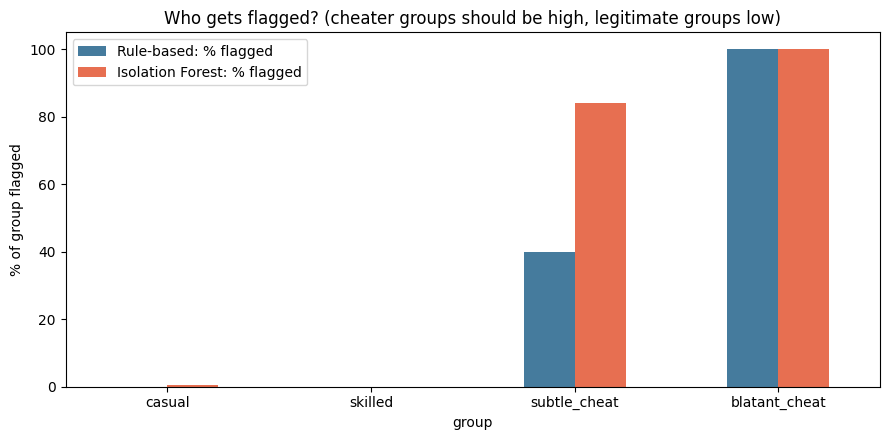

In [7]:
# Where does each detector flag people, by group? (the key view for fairness)
by_group = df.groupby("group")[["rule_flag", "iso_flag"]].mean().mul(100).round(1)
by_group.columns = ["Rule-based: % flagged", "Isolation Forest: % flagged"]
by_group = by_group.loc[["casual", "skilled", "subtle_cheat", "blatant_cheat"]]
display(by_group)

by_group.plot(kind="bar", figsize=(9, 4.5), color=["#457b9d", "#e76f51"])
plt.ylabel("% of group flagged")
plt.title("Who gets flagged? (cheater groups should be high, legitimate groups low)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**How to read this:** the two legitimate groups (`casual`, `skilled`) should stay near 0%, and the two cheater groups should be high. The rule-based baseline is precise but misses many subtle cheaters. The Isolation Forest catches more of the subtle ones, at the price of a small number of false positives. That trade-off is the central design problem in anti-cheat.

## 7. Choosing a threshold
Instead of a fixed contamination rate, rank players by anomaly score and choose how many to send for review. The precision-recall curve shows what each choice costs.

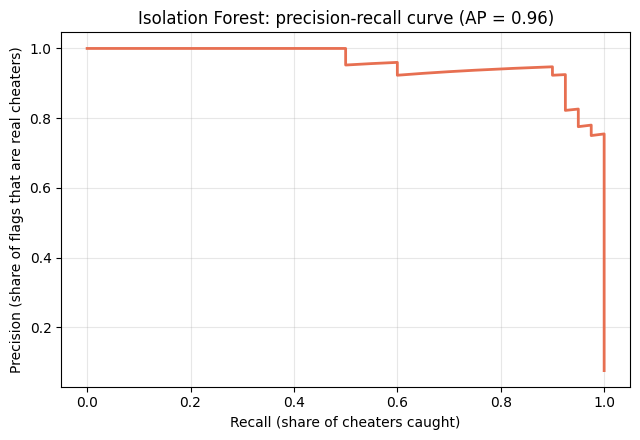

Reviewing the top 40 anomaly scores: 37 real cheaters, 3 innocent players.
group
subtle_cheat     22
blatant_cheat    15
casual            3


In [8]:
precision, recall, thresholds = precision_recall_curve(df.label, df.iso_score)
ap = average_precision_score(df.label, df.iso_score)

plt.figure(figsize=(6.5, 4.5))
plt.plot(recall, precision, color="#e76f51", lw=2)
plt.xlabel("Recall (share of cheaters caught)")
plt.ylabel("Precision (share of flags that are real cheaters)")
plt.title(f"Isolation Forest: precision-recall curve (AP = {ap:.2f})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# What if we only review the 40 highest-scoring players?
top40 = df.nlargest(40, "iso_score")
print(f"Reviewing the top 40 anomaly scores: {top40.label.sum()} real cheaters, {(top40.label == 0).sum()} innocent players.")
print(top40.group.value_counts().to_string())

## 8. Limitations (read this before drawing conclusions)
- **Synthetic data.** Real players are messier and cheaters adapt. The numbers above show the method, not real-world accuracy.
- **Known cheat rate.** The contamination value was set close to the true cheater rate, which a real system would not know.
- **Evaluated on the same data it was fitted on.** That is normal for unsupervised detection, but a real deployment needs separate evaluation data.
- **Simple features.** Real systems use richer signals, such as full aim trajectories over time.
- **Ethics.** Detection should lead to human review, not automatic bans, because false positives harm real players. Anything touching real player data needs privacy and consent safeguards.

## 9. Next steps
- Replace the simulation with real or open telemetry from a game server I control.
- Model aim trajectories over time with sequence models such as LSTMs.
- Add a second track for single-player integrity (licence-check bypass and tamper detection).
- Explain why a player was flagged (feature contributions) so reviewers can trust the alerts.

## References
Alayed, H., Frangoudes, F., & Neuman, C. (2013). Behavioral-based cheating detection in online first person shooters using machine learning techniques. *2013 IEEE Conference on Computational Intelligence in Games (CIG)*, 1-8.